1. Определить две бизнес-цели для набора данных по Вашему варианту задания.

Бизнес-цель 1: обучение модели предсказывать наличие диабета на основе данных - наличия беременности, глюкозы, аретиального давления, толщины кожи, инсулина, индекса массы тела, возраста

Бизнес-цель 2: Разработать и внедрить предиктивную модель для прогнозирования уровня кровяного давления на основе медицинских и демографических данных пациентов (беременности, уровень глюкозы, инсулин, индекс массы тела, наследственная предрасположенность к диабету, возраст и наличие диабета).


2. Определить цели технического проекта для каждой выделенной ранее бизнес цели.

Для Бизнес-цели 1:
    Определить и собрать набор данных, содержащий перечисленные признаки и метку класса (диабет: есть/нет).
    Обработать пропуски, выбросы, несбалансированность классов (SMOTE, undersampling/oversampling).
    Разделить данные.
    Обучить модель предсказывать наличие диабета.
    

    
Для Бизнес-цели 2: 
    Определить и собрать набор данных, содержащий перечисленные признаки и метку класса (диабет: есть/нет).
    Обработать пропуски, выбросы, несбалансированность классов (SMOTE, undersampling/oversampling).
    Разделить данные.
    Обучить модель предсказывать давление крови.


обучающая выборка:
  Всего samples: 537
  Класс 0: 350 (34.8%)
  Класс 1: 187 (34.8%)
  Соотношение: 1.87:1
данные сбалансированы, аугментация не требуется

валидационная выборка:
  Всего samples: 115
  Класс 0: 75 (34.8%)
  Класс 1: 40 (34.8%)
  Соотношение: 1.88:1
данные сбалансированы, аугментация не требуется

тестовая выборка:
  Всего samples: 116
  Класс 0: 75 (35.3%)
  Класс 1: 41 (35.3%)
  Соотношение: 1.83:1
данные сбалансированы, аугментация не требуется



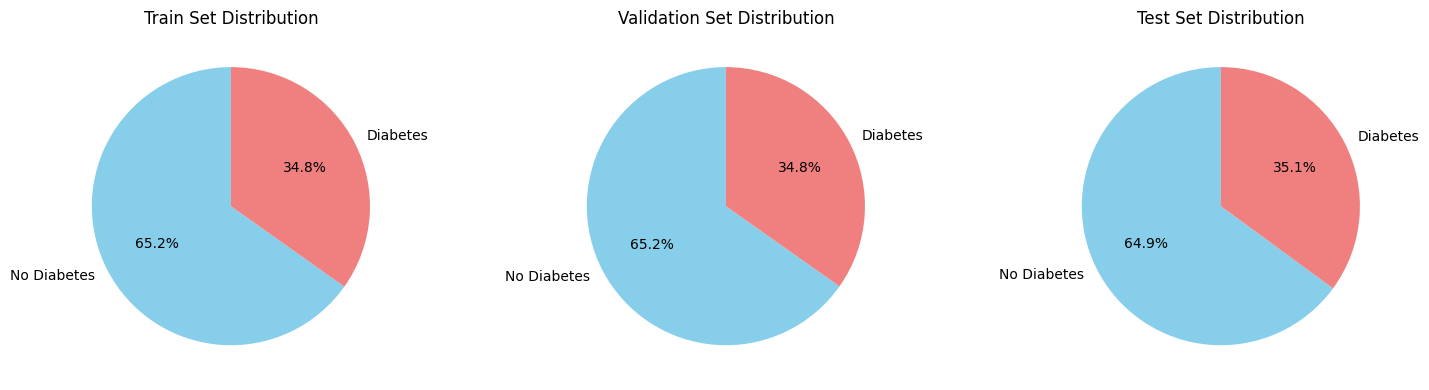

In [22]:
import pandas as pd
from sklearn.model_selection import train_test_split

import numpy as np
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('diabetes.csv')

df.dropna()
X = df[["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]]
y = df["Outcome"]

df_train, df_temp, y_train, y_temp = train_test_split(
        X, y, stratify=y, test_size=(1.0 - 0.7), random_state=42)

df_val, df_test, y_val, y_test = train_test_split(
    df_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)


# 5. Оценить сбалансированность выборок для каждого набора данных. Применить методы приращения (аугментации) данных при необходимости. 

def evaluate_balance(y_data, dataset_name):
    total = len(y_data)
    
    count_0 = sum(y_data == 0)
    count_1 = sum(y_data == 1)
    
    ratio_0 = count_0 / total * 100
    ratio_1 = count_1 / total * 100
    
    print(f"{dataset_name}:")
    print(f"  Всего samples: {total}")
    print(f"  Класс 0: {count_0} ({ratio_1:.1f}%)")
    print(f"  Класс 1: {count_1} ({ratio_1:.1f}%)")
    print(f"  Соотношение: {count_0/count_1:.2f}:1")
    print(f"{'данные несбалансированны, требуется аугментация' if ratio_1 < 20 else 'данные сбалансированны умеренно' if ratio_1 < 30 else 'данные сбалансированы, аугментация не требуется'}")
    print()
    
    return ratio_1


ratio_train = evaluate_balance(y_train, "обучающая выборка")
ratio_val = evaluate_balance(y_val, "валидационная выборка") 
ratio_test = evaluate_balance(y_test, "тестовая выборка")

# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

datasets = [('Train', y_train), ('Validation', y_val), ('Test', y_temp)]
colors = ['skyblue', 'lightcoral']

for i, (name, y_data) in enumerate(datasets):
    counts = [sum(y_data == 0), sum(y_data == 1)]
    axes[i].pie(counts, labels=['No Diabetes', 'Diabetes'], autopct='%1.1f%%', 
                colors=colors, startangle=90)
    axes[i].set_title(f'{name} Set Distribution')

plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)
model.fit(df_train, y_train)
preds = model.predict(df_test)
proba = model.predict_proba(df_test)[:, 1]


print(f"ROC_AUC: {roc_auc_score(y_test, proba)}")
print(f"F1: {f1_score(y_test, preds)}")
print(f"Accuracy: {model.score(df_test, y_test)}")



new_patient = {
    "Pregnancies": 2,
    "Glucose": 130,
    "BloodPressure": 80,
    "SkinThickness": 25,
    "Insulin": 100,
    "BMI": 32.4,
    "DiabetesPedigreeFunction": 0.45,
    "Age": 45
}
new_df = pd.DataFrame([new_patient])
print(model.predict(new_df))
    

ROC_AUC: 0.811869918699187
F1: 0.5915492957746479
Accuracy: 0.75
[1]


In [24]:
'''Выполнить процесс конструирования признаков для решения каждой из двух задач. Задача определяется совокупностью бизнес-цели и цели технического проекта.'''

from sklearn.preprocessing import StandardScaler

df_feature_construction = df.copy()


# тут дискретизация
df_feature_construction['Insulin_Group'] = pd.cut(df['Insulin'], 
                                bins=[-1, 140, 199, 300], 
                                labels=['normal', 'prediabetic_state', 'diabet'])

df_feature_construction['BMI_Group'] = pd.cut(df['BMI'], 
                                bins=[0, 18, 24.9, 29.9, 40], 
                                labels=['underweight', 'normal', 'overweight', 'obesity'])
df_feature_construction['Glucose_Status'] = pd.cut(df['Glucose'],
                                     bins=[0, 70, 100, 125, 200, 300],
                                     labels=['Hypoglycemia', 'Normal', 'Prediabetes', 
                                             'Diabetes', 'Severe_Diabetes'])

# тут one hot encoding
categorical_columns = [
    'Insulin_Group',
    'BMI_Group',
    'Glucose_Status'
]
df_feature_construction = pd.get_dummies(df_feature_construction, 
                            columns=categorical_columns,
                            drop_first=False) 

# преобразовываю bool в int
bool_columns = df_feature_construction.select_dtypes(include=['bool']).columns
df_feature_construction[bool_columns] = df_feature_construction[bool_columns].astype(int)

print(f"После one-hot encoding: {df_feature_construction.shape[1]} признаков")


#индекс инсулинорезистентности
df_feature_construction['HOMA_IR_Approx'] = (df['Glucose'] * df['Insulin']) / 405


numeric_features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
scaler = StandardScaler()
df_feature_construction[numeric_features] = scaler.fit_transform(df[numeric_features])
#print(df_feature_construction)

print(df_feature_construction.dtypes)

После one-hot encoding: 21 признаков
Pregnancies                        float64
Glucose                            float64
BloodPressure                      float64
SkinThickness                      float64
Insulin                            float64
BMI                                float64
DiabetesPedigreeFunction           float64
Age                                float64
Outcome                              int64
Insulin_Group_normal                 int64
Insulin_Group_prediabetic_state      int64
Insulin_Group_diabet                 int64
BMI_Group_underweight                int64
BMI_Group_normal                     int64
BMI_Group_overweight                 int64
BMI_Group_obesity                    int64
Glucose_Status_Hypoglycemia          int64
Glucose_Status_Normal                int64
Glucose_Status_Prediabetes           int64
Glucose_Status_Diabetes              int64
Glucose_Status_Severe_Diabetes       int64
HOMA_IR_Approx                     float64
dtype: object


In [25]:
import featuretools as ft
import pandas as pd
import woodwork as ww

def create_entityset_with_woodwork(df):
    df_new = df_feature_construction.copy()
    df_new.reset_index(drop=True, inplace=True)
    df_new["id"] = df_new.index
    
    df_new.ww.init(
        name='patients',
        index='id',
        logical_types={
            'Pregnancies': 'Integer',
            'Glucose': 'Double',
            'BloodPressure': 'Double',
            'SkinThickness': 'Double', 
            'Insulin': 'Double',
            'BMI': 'Double',
            'DiabetesPedigreeFunction': 'Double',
            'Age': 'Integer',
            'Outcome': 'Integer',
            'Insulin_Group_normal': 'Integer',
            'Insulin_Group_prediabetic_state': 'Integer',
            'Insulin_Group_diabet': 'Integer',
            'BMI_Group_underweight': 'Integer',
            'BMI_Group_normal': 'Integer',
            'BMI_Group_overweight': 'Integer', 
            'BMI_Group_obesity': 'Integer',
            'Glucose_Status_Hypoglycemia': 'Integer',
            'Glucose_Status_Normal': 'Integer',
            'Glucose_Status_Prediabetes': 'Integer',
            'Glucose_Status_Diabetes': 'Integer',
            'Glucose_Status_Severe_Diabetes': 'Integer',
            'HOMA_IR_Approx': 'Double'
        }
    )
    
    es = ft.EntitySet(id="diabetes_data")
    es = es.add_dataframe(dataframe=df_new)
    
    print(es)
    return es


es = create_entityset_with_woodwork(df)

Entityset: diabetes_data
  DataFrames:
    patients [Rows: 768, Columns: 23]
  Relationships:
    No relationships


In [26]:
import time
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)

def grade(df, title):
        print('-' * 30)
        print(title)
        
        df_temp = df.copy()
        df_temp.dropna()
        
        y = df_temp["Outcome"]
        X = df_temp.drop('Outcome', axis=1) 
        
        df_train, df_test, y_train, y_test = train_test_split(
                X, y, stratify=y, test_size=(1.0 - 0.7), random_state=42)
        
        
        start = time.time()
        model.fit(df_train, y_train)
        preds = model.predict(df_test)
        proba = model.predict_proba(df_test)[:, 1]
        print(f"Время обучения и предсказания: {time.time() - start:.2f} секунд\n")
        
        scores = cross_val_score(model, X, y, cv=5, scoring='roc_auc')
        print(f"Надежность: средний ROC-AUC: {scores.mean():.3f}, Стандартное отклонение: {scores.std():.3f}\n")
        
        print(f"ROC_AUC: {roc_auc_score(y_test, proba)}")
        print(f"F1: {f1_score(y_test, preds)}")
        print(f"Accuracy: {model.score(df_test, y_test)}\n\n")   
        
        
print(df.columns)
  
grade(df, "начальная таблица")       
grade(df_feature_construction, "Feature_construction")

df_featuretools, feature_defs = ft.dfs(
            entityset=es,
            target_dataframe_name="patients",
            max_depth=2,
            verbose=False
        )
grade(df_featuretools, "featuretools")



Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')
------------------------------
начальная таблица
Время обучения и предсказания: 0.12 секунд

Надежность: средний ROC-AUC: 0.825, Стандартное отклонение: 0.031

ROC_AUC: 0.8191769547325102
F1: 0.5972222222222222
Accuracy: 0.7489177489177489


------------------------------
Feature_construction
Время обучения и предсказания: 0.17 секунд

Надежность: средний ROC-AUC: 0.828, Стандартное отклонение: 0.029

ROC_AUC: 0.8381893004115226
F1: 0.6122448979591837
Accuracy: 0.7532467532467533


------------------------------
featuretools
Время обучения и предсказания: 0.14 секунд

Надежность: средний ROC-AUC: 0.814, Стандартное отклонение: 0.034

ROC_AUC: 0.8147325102880659
F1: 0.5753424657534246
Accuracy: 0.7316017316017316




In [27]:
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.ensemble import RandomForestClassifier
import time

model = RandomForestClassifier(random_state=42)
model.fit(df_train, y_train)
preds = model.predict(df_test)
proba = model.predict_proba(df_test)[:, 1]


print(f"ROC_AUC: {roc_auc_score(y_test, proba)}")
print(f"F1: {f1_score(y_test, preds)}")
print(f"Accuracy: {model.score(df_test, y_test)}")



new_patient = {
    "Pregnancies": 2,
    "Glucose": 130,
    "BloodPressure": 80,
    "SkinThickness": 25,
    "Insulin": 100,
    "BMI": 32.4,
    "DiabetesPedigreeFunction": 0.45,
    "Age": 45
}
new_df = pd.DataFrame([new_patient])
print(model.predict(new_df))


    

ROC_AUC: 0.811869918699187
F1: 0.5915492957746479
Accuracy: 0.75
[1]


2 Бизнес цель: обучение модели предсказывать кровяное давление на основе таких признаков, как количество беременностей, глюкоза, инсулин, индекса массы тела, генетической предрасположенности к диабету, возраста и наличия диабета

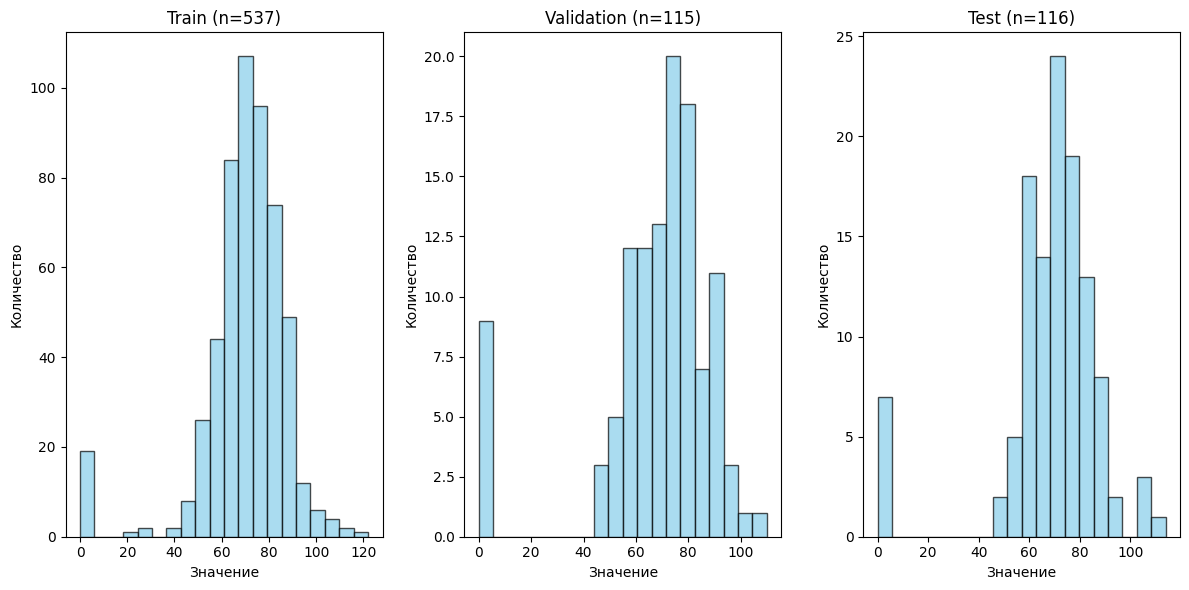

In [28]:
import pandas as pd
from sklearn.model_selection import train_test_split

import numpy as np
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('diabetes.csv')

'''df['BloodPressure_Group'] = pd.cut(
    df['BloodPressure'], 
    bins=[-1, 60, 80, 90, 120],
    labels=[
        'Severe_Hypotension',
        'Hypotension',
        'Elevated',
        'Normal'
    ]
) '''
df = df.dropna()     
                

X = df[["Pregnancies", "Glucose", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]]

y = df["BloodPressure"]


df_train, df_temp, y_train, y_temp = train_test_split(
        X, y, test_size=(1.0 - 0.7), random_state=42)

df_val, df_test, y_val, y_test = train_test_split(
    df_temp, y_temp, test_size=0.5, random_state=42)


# 5. Оценить сбалансированность выборок для каждого набора данных. Применить методы приращения (аугментации) данных при необходимости. 

def evaluate_splits(y_train, y_val, y_test):
    datasets = {
        "Train": y_train,
        "Validation": y_val,
        "Test": y_test
    }
    
    stats = {}
    for name, y in datasets.items():
        stats[name] = {
            "count": len(y),
            "mean": np.mean(y),
            "median": np.median(y),
            "std": np.std(y),
            "min": np.min(y),
            "max": np.max(y)
        }
    
    plt.figure(figsize=(12, 6))
    for i, (name, y) in enumerate(datasets.items(), 1):
        plt.subplot(1, 3, i)
        plt.hist(y, bins=20, alpha=0.7, color="skyblue", edgecolor="black")
        plt.title(f"{name} (n={len(y)})")
        plt.xlabel("Значение")
        plt.ylabel("Количество")
    plt.tight_layout()
    plt.show()

evaluate_splits(y_train, y_val, y_test)
        

In [29]:
'''Выполнить процесс конструирования признаков для решения каждой из двух задач. Задача определяется совокупностью бизнес-цели и цели технического проекта.'''

from sklearn.preprocessing import StandardScaler

df_feature_construction = df.copy()


# тут дискретизация
df_feature_construction['Insulin_Group'] = pd.cut(df['Insulin'], 
                                bins=[-1, 140, 199, 300], 
                                labels=['normal', 'prediabetic_state', 'diabet'])

df_feature_construction['BMI_Group'] = pd.cut(df['BMI'], 
                                bins=[0, 18, 24.9, 29.9, 40], 
                                labels=['underweight', 'normal', 'overweight', 'obesity'])
df_feature_construction['Glucose_Status'] = pd.cut(df['Glucose'],
                                     bins=[0, 70, 100, 125, 200, 300],
                                     labels=['Hypoglycemia', 'Normal', 'Prediabetes', 
                                             'Diabetes', 'Severe_Diabetes'])

# тут one hot encoding
categorical_columns = [
    'Insulin_Group',
    'BMI_Group',
    'Glucose_Status',
    'Outcome'
]
df_feature_construction = pd.get_dummies(df_feature_construction, 
                            columns=categorical_columns,
                            drop_first=False) 

# преобразовываю bool в int
bool_columns = df_feature_construction.select_dtypes(include=['bool']).columns
df_feature_construction[bool_columns] = df_feature_construction[bool_columns].astype(int)

print(f"После one-hot encoding: {df_feature_construction.shape[1]} признаков")


#индекс инсулинорезистентности
df_feature_construction['HOMA_IR_Approx'] = (df['Glucose'] * df['Insulin']) / 405


numeric_features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
scaler = StandardScaler()
df_feature_construction[numeric_features] = scaler.fit_transform(df[numeric_features])
#print(df_feature_construction)

print(df_feature_construction.dtypes)

После one-hot encoding: 22 признаков
Pregnancies                        float64
Glucose                            float64
BloodPressure                      float64
SkinThickness                      float64
Insulin                            float64
BMI                                float64
DiabetesPedigreeFunction           float64
Age                                float64
Insulin_Group_normal                 int64
Insulin_Group_prediabetic_state      int64
Insulin_Group_diabet                 int64
BMI_Group_underweight                int64
BMI_Group_normal                     int64
BMI_Group_overweight                 int64
BMI_Group_obesity                    int64
Glucose_Status_Hypoglycemia          int64
Glucose_Status_Normal                int64
Glucose_Status_Prediabetes           int64
Glucose_Status_Diabetes              int64
Glucose_Status_Severe_Diabetes       int64
Outcome_0                            int64
Outcome_1                            int64
HOMA_IR_Approx   

In [30]:
import featuretools as ft
import pandas as pd
import woodwork as ww

def create_entityset_with_woodwork(df):
    df_new = df_feature_construction.copy()
    df_new.reset_index(drop=True, inplace=True)
    df_new["id"] = df_new.index
    
    df_new.ww.init(
        name='patients',
        index='id',
        logical_types = {
            'Pregnancies': 'Integer',
            'Glucose': 'Double',
            'BloodPressure': 'Double',
            'SkinThickness': 'Double',
            'Insulin': 'Double',
            'BMI': 'Double',
            'DiabetesPedigreeFunction': 'Double',
            'Age': 'Integer',
            'Insulin_Group_normal': 'Integer',
            'Insulin_Group_prediabetic_state': 'Integer',
            'Insulin_Group_diabet': 'Integer',
            'BMI_Group_underweight': 'Integer',
            'BMI_Group_normal': 'Integer',
            'BMI_Group_overweight': 'Integer',
            'BMI_Group_obesity': 'Integer',
            'Glucose_Status_Hypoglycemia': 'Integer',
            'Glucose_Status_Normal': 'Integer',
            'Glucose_Status_Prediabetes': 'Integer',
            'Glucose_Status_Diabetes': 'Integer',
            'Glucose_Status_Severe_Diabetes': 'Integer',
            'Outcome_0': 'Integer',
            'Outcome_1': 'Integer',
            'HOMA_IR_Approx': 'Double'
        }
    )
    
    es = ft.EntitySet(id="diabetes_data")
    es = es.add_dataframe(dataframe=df_new)
    
    print(es)
    return es


es = create_entityset_with_woodwork(df)

Entityset: diabetes_data
  DataFrames:
    patients [Rows: 768, Columns: 24]
  Relationships:
    No relationships


In [ ]:
import time
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.utils import resample

model = RandomForestClassifier(random_state=42)        
        
print(df.columns)

def grade(df, name):
    #df_temp.copy(df)
    
    y = df["BloodPressure"]
    X = df.drop('BloodPressure', axis=1) 

    df_train, df_temp, y_train, y_temp = train_test_split(
            X, y, test_size=(1.0 - 0.7), random_state=42)

    df_val, df_test, y_val, y_test = train_test_split(
        df_temp, y_temp, test_size=0.5, random_state=42)

    model = LinearRegression()
    model.fit(df_train, y_train)

    y_pred = model.predict(df_test)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(name)
    print("Классические метрики:")
    print(f"MAE: {mae:.3f}")
    print(f"R²: {r2:.3f}\n")

    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(model, X, y, cv=cv, scoring='r2')
    print("Кросс-валидация (R²):")
    print(f"Среднее: {scores.mean():.3f}, Стд. отклонение: {scores.std():.3f}\n")

    n_bootstraps = 100
    predictions = []

    for i in range(n_bootstraps):
        X_resampled, y_resampled = resample(df_train, y_train, random_state=i)
        model.fit(X_resampled, y_resampled)
        predictions.append(model.predict(df_test))

    predictions = np.array(predictions)
    lower = np.percentile(predictions, 5, axis=0)
    upper = np.percentile(predictions, 95, axis=0)

    '''for i in range(8):
        print(f"Истинное: {y_test.iloc[i]:.2f}, "
            f"Предсказание: {y_pred[i]:.2f}, "
            f"Интервал: [{lower[i]:.2f}, {upper[i]:.2f}]")'''
        
  
df.dropna()
df_feature_construction.dropna()
df_featuretools.dropna()
grade(df, "начальная таблица")       
grade(df_feature_construction, "Feature_construction")

df_featuretools, feature_defs = ft.dfs(
            entityset=es,
            target_dataframe_name="patients",
            max_depth=2,
            verbose=False
        )
grade(df_featuretools, "featuretools")




Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')
начальная таблица
Классические метрики:
MAE: 11.936
R²: 0.216

Кросс-валидация (R²):
Среднее: 0.132, Стд. отклонение: 0.042

Истинное: 84.00, Предсказание: 67.67, Интервал: [65.29, 70.35]
Истинное: 60.00, Предсказание: 63.93, Интервал: [61.88, 66.13]
Истинное: 78.00, Предсказание: 83.34, Интервал: [78.97, 88.54]
Истинное: 64.00, Предсказание: 71.72, Интервал: [69.35, 75.10]
Истинное: 50.00, Предсказание: 68.09, Интервал: [65.28, 70.41]
Истинное: 74.00, Предсказание: 67.14, Интервал: [62.55, 71.87]
Истинное: 84.00, Предсказание: 80.15, Интервал: [77.62, 83.06]
Истинное: 75.00, Предсказание: 50.07, Интервал: [43.26, 59.21]
Feature_construction
Классические метрики:
MAE: 0.615
R²: 0.237

Кросс-валидация (R²):
Среднее: 0.117, Стд. отклонение: 0.059

Истинное: 0.77, Предсказание: 0.04, Интервал: [-0.12, 0.24]
Истинное: -0.47, Предск